In [11]:
from pathlib import Path
import json, platform, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import jax
import jax.numpy as jnp
from IPython.display import display

jax.config.update("jax_enable_x64", True)
ROOT = Path("sequential_ope_outputs")
FIG = ROOT / "figures"
TAB = ROOT / "reports"
for folder in (FIG, TAB): folder.mkdir(parents=True, exist_ok=True)
SEED = 20261107
H, GAMMA, S, A = 8, 0.97, 5, 2

## Dynamic system

The state represents an operating condition and the action represents a control choice.

Actions change both the immediate cost and the next state.

We keep the transition law known so that the true policy value is available for every experiment.

In [2]:
# Transition probabilities P[state, action, next_state].
P = np.zeros((S,A,S))
for s in range(S):
    for a in range(A):
        center = np.clip(s + (1 if a == 0 else -1), 0, S-1)
        P[s,a,center] += .70
        P[s,a,s] += .20
        P[s,a,np.clip(center + (1 if a == 0 else -1),0,S-1)] += .10
assert np.allclose(P.sum(axis=2), 1)
# Reward is negative operating cost. A higher value is better.
R = np.array([[-(0.3*s + 0.15*s*s + .3), -(0.3*s + 0.15*s*s + .85)] for s in range(S)])
INIT = np.array([.30,.25,.20,.15,.10])
behavior = np.column_stack([np.linspace(.68,.42,S), np.linspace(.32,.58,S)])
target = np.column_stack([np.linspace(.50,.20,S), np.linspace(.50,.80,S)])

def exact_value(policy):
    p = jnp.asarray(P); r = jnp.asarray(R); pi = jnp.asarray(policy)
    v = jnp.zeros(S)
    for _ in range(H):
        q = r + GAMMA*jnp.einsum('sak,k->sa',p,v)
        v = jnp.sum(pi*q,axis=1)
    return float(jnp.asarray(INIT) @ v)

TRUTH = exact_value(target)
print('Exact target policy value:', round(TRUTH,5))
print('Exact behavior policy value:', round(exact_value(behavior),5))

Exact target policy value: -11.0527
Exact behavior policy value: -14.00201


## Logged trajectories

Each episode starts from the same initial distribution.

The behavior policy selects the actions and we record their probabilities.

Reward noise enters after the action and has zero conditional mean.

In [3]:
def simulate(n, pi, seed, noise=1.0):
    rng=np.random.default_rng(seed)
    states=np.empty((n,H+1),dtype=np.int32)
    actions=np.empty((n,H),dtype=np.int32)
    rewards=np.empty((n,H))
    states[:,0]=rng.choice(S,size=n,p=INIT)
    for t in range(H):
        s=states[:,t]
        a=(rng.random(n)>pi[s,0]).astype(np.int32)
        actions[:,t]=a
        rewards[:,t]=R[s,a]+rng.normal(0,noise,n)
        u=rng.random(n)
        cdf=np.cumsum(P[s,a,:],axis=1)
        states[:,t+1]=(u[:,None]>cdf).sum(axis=1).astype(np.int32)
    return states,actions,rewards

s,a,r=simulate(1500,behavior,SEED)
print('Episodes:',len(s),'| action frequencies:',np.bincount(a.ravel())/a.size)
print('Observed discounted reward:',np.mean(np.sum(r*GAMMA**np.arange(H),axis=1)))

Episodes: 1500 | action frequencies: [0.55608333 0.44391667]
Observed discounted reward: -13.886904467358043


## Estimators

The direct method estimates a time-dependent action value using backward regression.

Per-decision importance sampling uses the recorded action probabilities.

The doubly robust estimate combines the fitted value with a weighted correction for each decision.

The outcome models are fitted on separate episodes from those used for evaluation.

In [4]:
def fit_q(states, actions, rewards, target_pi, ridge=0.5):
    # Independent, time-indexed fitted Q evaluation, with pooled state-action cells.
    n=len(states)
    q=np.zeros((H,S,A)); vnext=np.zeros(S)
    for t in range(H-1,-1,-1):
        y=rewards[:,t]+GAMMA*vnext[states[:,t+1]]
        for st in range(S):
            for act in range(A):
                m=(states[:,t]==st)&(actions[:,t]==act)
                # Shrink toward the pooled reward-to-go mean to stabilize sparse cells.
                q[t,st,act]=(y[m].sum()+ridge*y.mean())/(m.sum()+ridge)
        vnext=np.sum(target_pi*q[t],axis=1)
    return q

def contributions(states,actions,rewards,bpi,tpi,q):
    n=len(states); w=np.ones(n); pd=np.zeros(n); dr=np.zeros(n)
    v=np.einsum('sa,tsa->ts',tpi,q)
    dr[:]=v[0,states[:,0]]
    for t in range(H):
        st=states[:,t]; act=actions[:,t]
        w *= tpi[st,act]/bpi[st,act]
        pd += GAMMA**t*w*rewards[:,t]
        vnext=v[t+1,states[:,t+1]] if t+1<H else np.zeros(n)
        dr += GAMMA**t*w*(rewards[:,t]+GAMMA*vnext-q[t,st,act])
    return pd,dr,w

def estimate(states,actions,rewards,bpi,tpi,folds=2):
    n=len(states); rng=np.random.default_rng(2718+n)
    perm=rng.permutation(n); groups=np.array_split(perm,folds)
    dm=np.empty(n); pd=np.empty(n); dr=np.empty(n); terminal_w=np.empty(n)
    for group in groups:
        train=np.setdiff1d(np.arange(n),group,assume_unique=True)
        q=fit_q(states[train],actions[train],rewards[train],tpi)
        dm[group]=np.sum(tpi[states[group,0]]*q[0,states[group,0]],axis=1)
        pd[group],dr[group],terminal_w[group]=contributions(states[group],actions[group],rewards[group],bpi,tpi,q)
    return {'Direct':dm,'PDIS':pd,'DR':dr},terminal_w

def summary(contrib,truth):
    x=np.asarray(contrib); est=x.mean(); se=x.std(ddof=1)/np.sqrt(len(x))
    return {'estimate':est,'se':se,'lower':est-1.96*se,'upper':est+1.96*se,
            'error':est-truth,'covered':float(abs(est-truth)<=1.96*se)}

parts,weights=estimate(s,a,r,behavior,target)
print(pd.DataFrame({k:summary(v,TRUTH) for k,v in parts.items()}).T.round(4))

        estimate      se    lower    upper   error  covered
Direct  -10.9542  0.0887 -11.1282 -10.7803  0.0985      1.0
PDIS    -10.7571  0.2039 -11.1567 -10.3574  0.2956      1.0
DR      -10.8576  0.1389 -11.1299 -10.5853  0.1951      1.0


## Monte Carlo study

We repeat the full experiment with new independent datasets.

Bias, RMSE, interval coverage and interval width are calculated against the exact policy value.

The standard errors use independent episodes as the sampling units.

In [5]:
SCENARIOS={
    'standard':(behavior,target),
    'limited overlap':(np.column_stack([np.linspace(.92,.78,S),np.linspace(.08,.22,S)]),target),
    'near behavior':(behavior, .75*behavior+.25*target)
}
REPS=60
SAMPLE_SIZES=[400,1200]
rows=[]; runs=[]
t0=time.time()
for scenario,(bpi,tpi) in SCENARIOS.items():
    true=exact_value(tpi)
    for size in SAMPLE_SIZES:
        for rep in range(REPS):
            st,ac,re=simulate(size,bpi,SEED+rep*10007+size*3+len(scenario))
            pieces,w=estimate(st,ac,re,bpi,tpi)
            for method,x in pieces.items():
                record=summary(x,true)
                rows.append({'scenario':scenario,'n':size,'rep':rep,'method':method,'truth':true,**record})
        print('Finished',scenario,'n=',size)
results=pd.DataFrame(rows)
results.to_csv(TAB/'monte_carlo_runs.csv',index=False)
agg=results.groupby(['scenario','n','method']).agg(
    bias=('error','mean'),rmse=('error',lambda x:np.sqrt(np.mean(np.square(x)))),
    coverage=('covered','mean'),mean_se=('se','mean'),replicates=('rep','count')).reset_index()
agg.to_csv(TAB/'monte_carlo_summary.csv',index=False)
print('Runtime:',round(time.time()-t0,1),'seconds')
display(agg.round(4))

Finished standard n= 400
Finished standard n= 1200
Finished limited overlap n= 400
Finished limited overlap n= 1200
Finished near behavior n= 400
Finished near behavior n= 1200
Runtime: 1.4 seconds


,scenario,n,method,bias,rmse,coverage,mean_se,replicates
0,limited overlap,400,DR,0.2733,11.1032,0.5667,3.7167,60
1,limited overlap,400,Direct,-5.1297,5.1622,0.0000,0.1213,60
2,limited overlap,400,PDIS,0.4560,3.2728,0.7667,2.2265,60
3,limited overlap,1200,DR,-0.7206,2.1633,0.5500,1.3583,60
4,limited overlap,1200,Direct,-3.1862,3.2092,0.0000,0.0835,60
5,limited overlap,1200,PDIS,-0.3808,4.0910,0.9000,2.1150,60
6,near behavior,400,DR,-0.0639,0.2681,0.9333,0.2791,60
7,near behavior,400,Direct,-0.0943,0.2907,0.7833,0.1849,60
8,near behavior,400,PDIS,-0.0498,0.2825,0.9500,0.2896,60
9,near behavior,1200,DR,0.0055,0.1351,0.9667,0.1590,60


,scenario,n,method,bias,rmse,coverage,mean_se,replicates
0,limited overlap,400,DR,0.2733,11.1032,0.5667,3.7167,60
1,limited overlap,400,Direct,-5.1297,5.1622,0.0000,0.1213,60
2,limited overlap,400,PDIS,0.4560,3.2728,0.7667,2.2265,60
3,limited overlap,1200,DR,-0.7206,2.1633,0.5500,1.3583,60
4,limited overlap,1200,Direct,-3.1862,3.2092,0.0000,0.0835,60
5,limited overlap,1200,PDIS,-0.3808,4.0910,0.9000,2.1150,60
6,near behavior,400,DR,-0.0639,0.2681,0.9333,0.2791,60
7,near behavior,400,Direct,-0.0943,0.2907,0.7833,0.1849,60
8,near behavior,400,PDIS,-0.0498,0.2825,0.9500,0.2896,60
9,near behavior,1200,DR,0.0055,0.1351,0.9667,0.1590,60


## Accuracy and coverage

RMSE shows the typical distance from the known target value.

Coverage checks whether the nominal 95% intervals contain the truth across repeated datasets.

The weaker-overlap setting tests how quickly the weighted estimates lose precision.

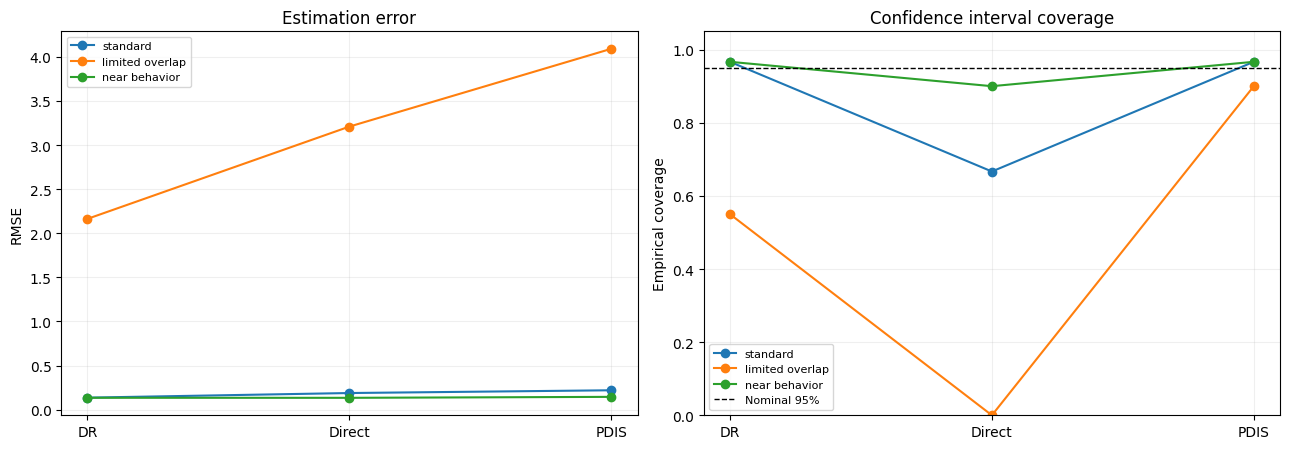

In [6]:
fig,axes=plt.subplots(1,2,figsize=(13,4.6))
for scenario in SCENARIOS:
    sub=agg[(agg.scenario==scenario)&(agg.n==1200)]
    axes[0].plot(sub.method,sub.rmse,marker='o',label=scenario)
    axes[1].plot(sub.method,sub.coverage,marker='o',label=scenario)
axes[0].set(ylabel='RMSE',title='Estimation error')
axes[1].axhline(.95,color='black',ls='--',lw=1,label='Nominal 95%')
axes[1].set(ylabel='Empirical coverage',ylim=(0,1.05),title='Confidence interval coverage')
for ax in axes:ax.grid(alpha=.2);ax.legend(fontsize=8)
fig.tight_layout();fig.savefig(FIG/'accuracy_coverage.png',dpi=190);plt.show()

## Sampling distributions

The repeated estimates reveal both systematic error and sampling variation.

The reference line is the exact value, not an estimate from the logged data.

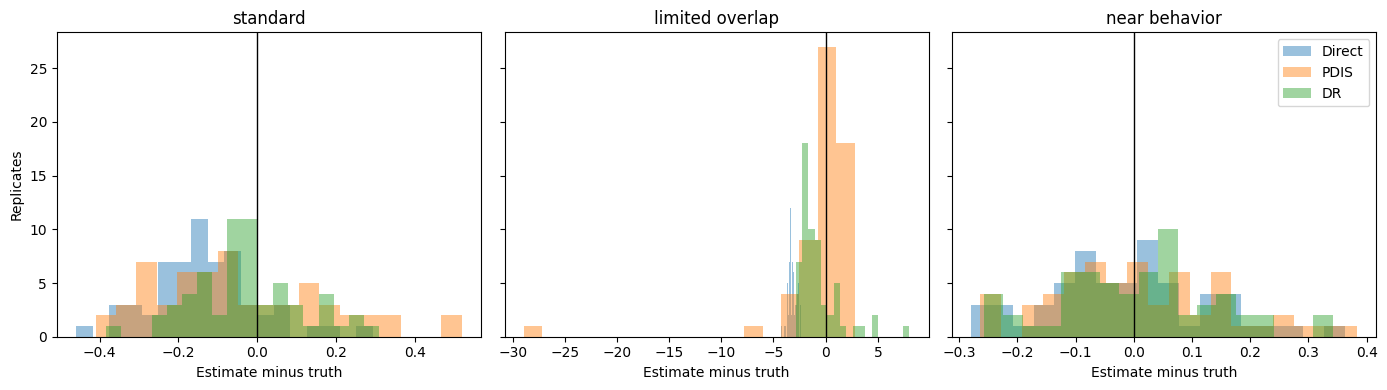

In [7]:
fig,axes=plt.subplots(1,3,figsize=(14,4),sharey=True)
for ax,(scenario,_) in zip(axes,SCENARIOS.items()):
    d=results[(results.scenario==scenario)&(results.n==1200)]
    for method in ['Direct','PDIS','DR']:
        ax.hist(d[d.method==method].error,bins=18,alpha=.45,label=method)
    ax.axvline(0,color='black',lw=1);ax.set(title=scenario,xlabel='Estimate minus truth')
axes[0].set_ylabel('Replicates');axes[-1].legend()
fig.tight_layout();fig.savefig(FIG/'sampling_distributions.png',dpi=190);plt.show()

## Overlap diagnostics

The cumulative importance weights describe how much the target policy differs from the logged behavior.

Effective sample size is reported for each decision step.

A small value means that only a few trajectories dominate the weighted estimate.

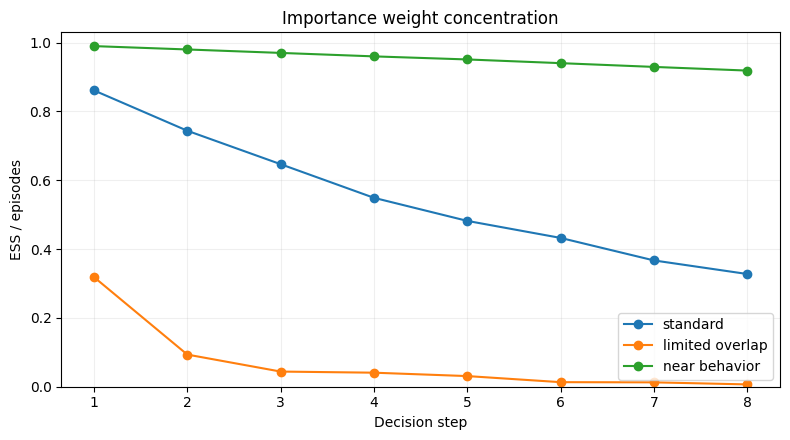

In [8]:
fig,ax=plt.subplots(figsize=(8,4.5))
weight_report=[]
for name,(bpi,tpi) in SCENARIOS.items():
    st,ac,re=simulate(4000,bpi,SEED+900+len(name))
    w=np.ones(len(st));ess=[]
    for t in range(H):
        w*=tpi[st[:,t],ac[:,t]]/bpi[st[:,t],ac[:,t]]
        ess.append(w.sum()**2/np.sum(w*w))
        weight_report.append({'scenario':name,'step':t+1,'ess':ess[-1],'ess_fraction':ess[-1]/len(w)})
    ax.plot(np.arange(1,H+1),np.array(ess)/len(w),marker='o',label=name)
ax.set(xlabel='Decision step',ylabel='ESS / episodes',ylim=(0,1.03),title='Importance weight concentration')
ax.legend();ax.grid(alpha=.2)
fig.tight_layout();fig.savefig(FIG/'overlap_ess.png',dpi=190);plt.show()
pd.DataFrame(weight_report).to_csv(TAB/'overlap_diagnostics.csv',index=False)

## Sample size

We compare the smaller and larger datasets under the same design.

The results show which gains come from additional logged episodes and which errors remain under weak overlap.

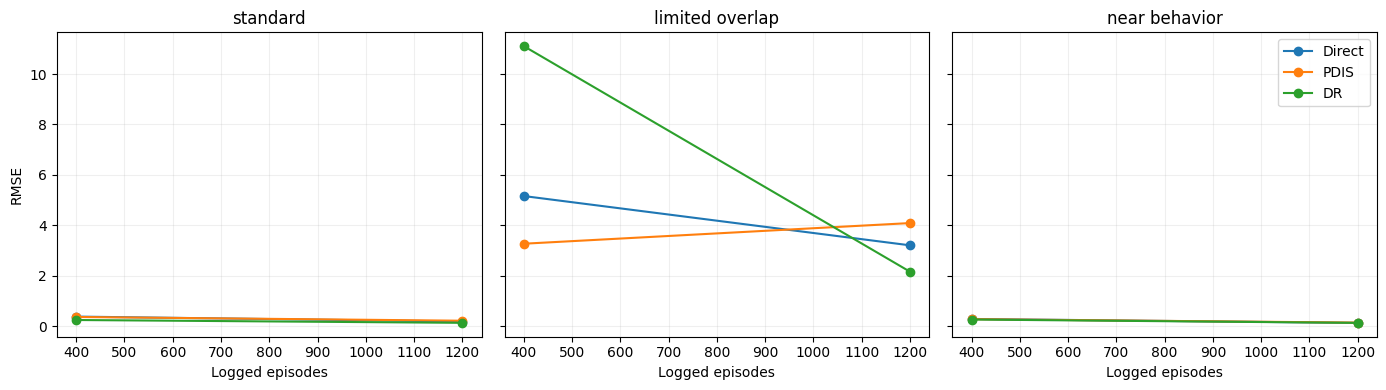

In [9]:
fig,axes=plt.subplots(1,3,figsize=(14,4),sharey=True)
for ax,(scenario,_) in zip(axes,SCENARIOS.items()):
    sub=agg[agg.scenario==scenario]
    for method in ['Direct','PDIS','DR']:
        d=sub[sub.method==method].sort_values('n')
        ax.plot(d.n,d.rmse,marker='o',label=method)
    ax.set(title=scenario,xlabel='Logged episodes');ax.grid(alpha=.2)
axes[0].set_ylabel('RMSE');axes[-1].legend()
fig.tight_layout();fig.savefig(FIG/'sample_size.png',dpi=190);plt.show()

## Checks and saved results

We verify the probability distributions and the repeated-experiment counts.

The summary files and figures are saved alongside the notebook outputs.

This experiment uses observed states, known action probabilities and a correctly specified simulator. Hidden confounding and learned propensities are not part of this run.

In [12]:
assert np.allclose(P.sum(axis=-1),1)
assert all(np.allclose(x.sum(axis=1),1) for pair in SCENARIOS.values() for x in pair)
assert len(results)==len(SCENARIOS)*len(SAMPLE_SIZES)*REPS*3
assert np.isfinite(results[['estimate','se','lower','upper']].to_numpy()).all()
metadata={'seed':SEED,'horizon':H,'discount':GAMMA,'states':S,'actions':A,
          'replications':REPS,'sample_sizes':SAMPLE_SIZES,'scenarios':list(SCENARIOS),
          'estimators':['Direct','PDIS','DR'],'crossfit_folds':2,
          'interval':'episode-level normal approximation, 1.96 standard errors',
          'limitations':['known behavior probabilities','fully observed state','finite horizon',
                         'normal approximation may undercover under extreme weight tails'],
          'python':platform.python_version(),'jax':jax.__version__}
(ROOT/'experiment_metadata.json').write_text(json.dumps(metadata,indent=2))
print('Figures:',len(list(FIG.glob('*.png'))),'| CSV reports:',len(list(TAB.glob('*.csv'))))

Figures: 4 | CSV reports: 3
